---
# Drills

The drills follow the topics from the workshop, in the same order. Each one is short and
tests one idea. Run your cell and compare it with the expected output.

---
## Topic 1 · Classes and objects
*Walkthrough: `01 - Classes and Objects`*

### D1. Define a class and create an object

1. Define a class `Record` with `__init__(self, label, value, limit)` that stores all three as
   attributes (`self.label = label`, and so on).
2. Create one object: `r1 = Record("R-001", 87.0, 100.0)`.
3. Print its three attributes.

**Expected output:** `R-001 87.0 100.0`

In [2]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
r1 = Record("R-001", 87.0, 100.0)
print(r1.label)
print(r1.value)
print(r1.limit)

R-001
87.0
100.0


### D2. Each object is separate

Using your `Record` class from D1:

1. Create a second object: `r2 = Record("R-002", 120.0, 100.0)`.
2. Change `r1.value` to `95.0`.
3. Print `r1.value` and `r2.value`.

**Expected output:** `95.0 120.0` (changing `r1` did not change `r2`)

In [2]:
r2 = Record("R-002", 120.0, 100.0)
r1.value = 95.0
print(r1.value, r2.value)


95.0 120.0


### D3. A dict and an object, side by side

1. Create `record_dict = {"label": "R-001", "value": 87.0}` and `record_obj = Record("R-001", 87.0, 100.0)`.
2. Print the label from each one.
3. Add a comment describing how the two ways of getting the label are different.

**Expected output:** `R-001`, then `R-001`

In [3]:
record_dict = {"label":"R-001", "value": 87.0}
record_obj = Record("R-001", 87.0, 100.0)
print(record_obj.label)
print(record_dict["label"])

R-001
R-001


### D4. Fix the class that stores nothing

This class looks right, but `__init__` never stores anything on the object, so the last line fails.
Fix it so that `r.label` works.

**Expected output after your fix:** `R-001`

In [4]:
# D4
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit

r = Record("R-001", 87.0, 100.0)
print(r.label)

R-001


---
## Topic 2 · Methods
*Walkthrough: `02 - Methods`*

### D5. Add a method

1. Add a method `summary(self)` to the class below. It **returns** a string like `R-001: 87.0/100.0`,
   built from `self.label`, `self.value` and `self.limit`.
2. Create a record and print the result of calling `.summary()` on it.

**Expected output:** `R-001: 87.0/100.0`

In [11]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
    def summary(self):
        result = self.label + " : "+ str(self.value) + "/" + str(self.limit)
        return result
r1 = Record("R-001", 87.0, 100.0)
print(r1.summary())

R-001 : 87.0/100.0


### D6. `self` is whichever object made the call

1. Copy your class from D5 and add a method `status(self)` that returns `"OVER LIMIT"` (100% or more),
   `"WARNING"` (90% or more) or `"OK"`, worked out from `self.value` and `self.limit`.
2. Create three records and print each one's `.status()`:

| Record | Expected output |
|---|---|
| `Record("R-001", 87.0, 100.0)` | `OK` |
| `Record("R-002", 120.0, 100.0)` | `OVER LIMIT` |
| `Record("R-003", 95.0, 100.0)` | `WARNING` |

In [4]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
    def status(self):
        percent = (self.value / self.limit) * 100
        if percent >=100:
            return "OVER LIMIT"
        elif percent >= 90:
            return "WARNING"
        else:
            return "OK"
r1 = Record("R-001", 87.0, 100.0)
r2 = Record("R-002", 120.0, 100.0)
r3 = Record("R-003", 97.0, 100.0)
print(r1.status())
print(r2.status())
print(r3.status())

OK
OVER LIMIT
WARNING


### D7. One method calls another

1. Copy your class from D6 and add a method `percent(self)` that returns `(self.value / self.limit) * 100`.
2. Change `status(self)` so it uses `self.percent()` instead of working out the percentage itself.
3. Create `Record("R-001", 87.0, 100.0)` and print its `.percent()` and `.status()`.

**Expected output:** `87.0`, then `OK`

In [13]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
    def percent(self):
        percent = (self.value / self.limit) * 100
        return percent
    def status(self):
        percentage = self.percent()
        if percentage >=100:
            return "OVER LIMIT"
        elif percentage >= 90:
            return "WARNING"
        else:
            return "OK"
r4 = Record("R-001", 87.0, 100.0)
print(r4.percent())
print(r4.status())

87.0
OK


### D8. A method can change its own object

1. Define a class `Checker`. In `__init__(self)`, set `self.over_limit_count = 0`.
2. Add a method `check(self, value, limit)` that adds 1 to `self.over_limit_count` when `value` is
   greater than `limit`.
3. Create one `Checker`, call `.check()` three times with `(87, 100)`, `(120, 100)` and `(130, 100)`,
   then print `over_limit_count`.

**Expected output:** `2`

In [23]:
class Checker:
    def __init__(self, over_limit_count):
        self.over_limit_count = 0

    def check(self, value, limit):
        if value > limit:
            self.over_limit_count += 1
            return self.over_limit_count
record = Checker(0)
record.check( 87.0, 100)
record.check(120, 100)
record.check(130, 100)

2

 ---
## Topic 3 · Many objects together
*Walkthrough: `03 - Many Objects Together`*

### D9. A list of objects

1. Using your `Record` class from D7, create a list of three records:
   `R-001` (87.0), `R-002` (120.0) and `R-003` (45.0), each with a limit of 100.0.
2. Loop over the list and print each record's label and status.

**Expected output:**
```
R-001 OK
R-002 OVER LIMIT
R-003 OK
```

In [26]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
    def percent(self):
        percent = (self.value / self.limit) * 100
        return percent
    def status(self):
        percentage = self.percent()
        if percentage >=100:
            return "OVER LIMIT"
        elif percentage >= 90:
            return "WARNING"
        else:
            return "OK"
Records = [Record("R-001",87.0, 100.0),Record("R-002", 120,100.0), Record("R-003", 45.0, 100.0)]
for rec in Records:
    status = rec.status()
    print(rec.label, status)

R-001 OK
R-002 OVER LIMIT
R-003 OK


### D10. A class-level counter

1. Define a new, small class `Counted`. Directly under the `class` line (not inside `__init__`),
   add `count = 0`.
2. In `__init__(self)`, add 1 to `Counted.count`.
3. Create three `Counted` objects, then print `Counted.count`.

**Expected output:** `3`

Add a comment explaining why the count is shared by every object instead of each object having its own.

In [27]:
class Counted:
    count = 0
    def __init__(self):
        Counted.count +=1
obj1 = Counted()
obj2 = Counted()
obj3 = Counted()
print(Counted.count)

3


### D11. Load objects from a file

`records_sample.txt` (in this `LAB` folder) has one record per line, like `R-001,87,100`.

1. Write `load_records(path)` that reads the file and returns a list of `Record` objects
   (convert `value` and `limit` with `float()`).
2. Loop over the list and print each record's label and status.

**Expected output:** the same three lines as D9.

In [2]:

def load_records(path):
    records = []
    with open(path, "r") as file:
        for line in file:
            label,value,limit = line.strip().split(",")
            records.append(Record(label, float(value), float(limit)))
    return records
records = load_records("records_sample.txt")
for rec in records:
  print(rec.label, rec.status())



R-001 OK
R-002 OVER LIMIT
R-003 OK


---
## Challenge · for a first

*These combine several ideas from this week. There are no step-by-step instructions.*

### C1. Count the records over the limit

Add a method `is_over(self)` to `Record` that returns `True` or `False`. Load `records_sample.txt` with
`load_records` from D11, use `is_over()` to count how many records are over their limit, and print a
one-line summary.

**Expected output:** `1 of 3 records are OVER LIMIT`

In [3]:
class Record:
    def __init__(self, label, value, limit):
        self.label = label
        self.value = value
        self.limit = limit
    def percent(self):
        percent = (self.value / self.limit) * 100
        return percent
    def status(self):
        percentage = self.percent()
        if percentage >=100:
            return "OVER LIMIT"
        elif percentage >= 90:
            return "WARNING"
        else:
            return "OK"
    def is_over(self):
        if self.percent() >= 100:
            return True


records = load_records("records_sample.txt")
count = 0
for rec in records:
    if rec.is_over() == True:
        count += 1
print(f"{count} of {len(records)} records are OVER LIMIT")


1 of 3 records are OVER LIMIT


### C2. An account that locks

Write a class `Account` with a `username` and a count of failed logins that starts at 0.
It has two methods:

- `fail(self)`: adds 1 to the failed logins
- `locked(self)`: returns `True` if there have been 3 or more failed logins

**Test it:**

| Code | Expected output |
|---|---|
| an account for `"anna"` with `.fail()` called 3 times, then `print(anna.locked())` | `True` |
| an account for `"ben"` with `.fail()` called once, then `print(ben.locked())` | `False` |

In [48]:
class Account:
    def __init__(self, username, failed_logins):
        self.username = username
        self.failed_logins = 0
    def fail(self):
        self.failed_logins += 1
    def locked(self):
        if self.failed_logins >= 3:
            return True
        else:
            return False
anna = Account("Anna", 0)
anna.fail()
anna.fail()
anna.fail()
print(anna.locked())
ben = Account("Ben", 0)
ben.fail()
print(ben.locked())

True
False


---
## 2. Add your cheat sheet notes here

Take a clear photo of your **whole** cheat sheet page (your notes for Weeks 1–5), then click into
this cell and paste it (`Ctrl+V` / `Cmd+V`), or drag the image file in.

*(paste here)*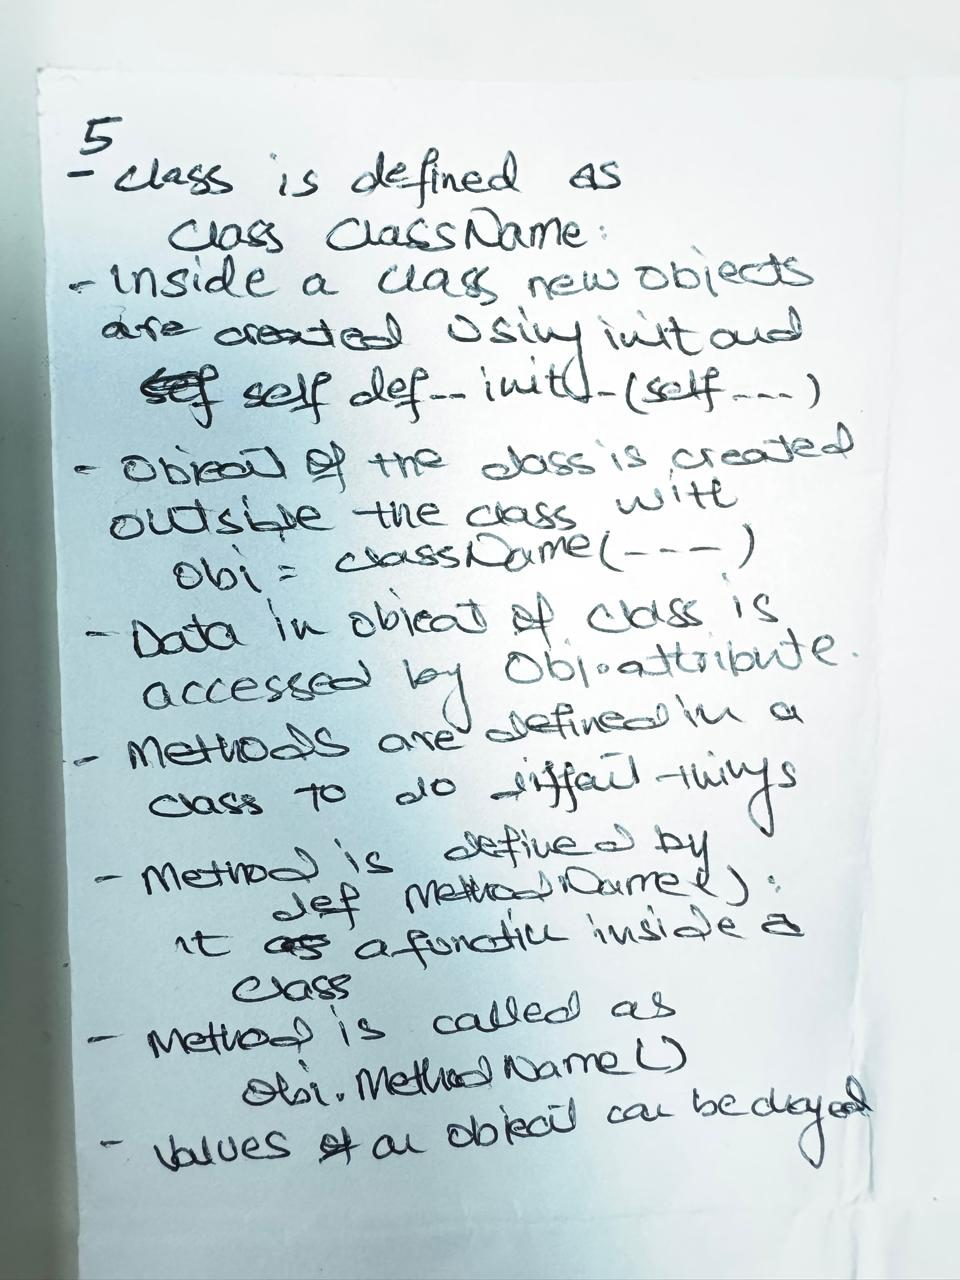